In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import plotly.express as px
import plotly.graph_objects as go
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Aesthetics
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

print("Statistical and visualization packages loaded successfully.")

Statistical and visualization packages loaded successfully.


In [2]:
# Load dataset with robust relative path handling
data_file = "womens_clothing_regression_dataset.csv"
if not os.path.exists(data_file):
    data_file = os.path.join("23-10-2026", "Task 1", "womens_clothing_regression_dataset.csv")

df = pd.read_csv(data_file)
print(f"Dataset loaded successfully: {df.shape[0]} rows, {df.shape[1]} columns")

features = [
    'Length_of_Membership',
    'Time_on_App',
    'Avg_Session_Length',
    'Annual_Orders',
    'Avg_Order_Value',
    'Age'
]
df['Inter_App_x_Tenure'] = df['Time_on_App'] * df['Length_of_Membership']
model_features = features + ['Inter_App_x_Tenure']
target = 'Yearly_Amount_Spent'

X = sm.add_constant(df[model_features])
y = df[target]

ols_res = sm.OLS(y, X).fit()
pred_summary = ols_res.get_prediction(X).summary_frame(alpha=0.05)

df['Predicted_Spend'] = pred_summary['mean']
df['CI_Lower'] = pred_summary['mean_ci_lower']
df['CI_Upper'] = pred_summary['mean_ci_upper']
df['PI_Lower'] = pred_summary['obs_ci_lower']
df['PI_Upper'] = pred_summary['obs_ci_upper']

df['Residual'] = df[target] - df['Predicted_Spend']
df['Absolute_Error'] = np.abs(df['Residual'])
df['Percentage_Error'] = (df['Absolute_Error'] / df[target]) * 100.0

# Define Customer Cohorts for Subgroup Bias Analysis (CRITICAL DEFINITION)
age_bins = [17, 30, 45, 60, 120]
age_labels = ['Gen Z / Young (18-30)', 'Early Career (31-45)', 'Mature (46-60)', 'Senior (61+)']
df['Age_Cohort'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels)

app_bins = [0, 11.5, 13.0, 30.0]
app_labels = ['Low App Usage (< 11.5m)', 'Average App Usage (11.5-13m)', 'High App Usage (> 13m)']
df['App_Usage_Cohort'] = pd.cut(df['Time_on_App'], bins=app_bins, labels=app_labels)

if 'Department Name' in df.columns:
    df['Department Name'] = df['Department Name'].fillna('Tops')

r2 = r2_score(y, df['Predicted_Spend'])
rmse = np.sqrt(mean_squared_error(y, df['Predicted_Spend']))
mae = mean_absolute_error(y, df['Predicted_Spend'])
print(f"Model Estimation Complete: R^2 = {r2:.4f}, RMSE = ${rmse:.2f}, MAE = ${mae:.2f}")
print("Defined columns on dataframe: ['Age_Cohort', 'App_Usage_Cohort', 'Predicted_Spend', 'Residual', 'Absolute_Error']")

Dataset loaded successfully: 23465 rows, 20 columns
Model Estimation Complete: R^2 = 0.9648, RMSE = $27.61, MAE = $21.93
Defined columns on dataframe: ['Age_Cohort', 'App_Usage_Cohort', 'Predicted_Spend', 'Residual', 'Absolute_Error']


In [3]:
bins = [0, 15, 35, 60, np.inf]
labels = ['Low (< $15)', 'Moderate ($15 - $35)', 'High ($35 - $60)', 'Extreme Outlier (> $60)']
df['Error_Magnitude_Category'] = pd.cut(df['Absolute_Error'], bins=bins, labels=labels)

error_summary = df.groupby('Error_Magnitude_Category', observed=False).agg(
    Count=('Residual', 'count'),
    Percentage=('Residual', lambda x: round(len(x) / len(df) * 100, 2)),
    Mean_Actual_Spend=('Yearly_Amount_Spent', lambda x: round(x.mean(), 2)),
    Mean_Predicted_Spend=('Predicted_Spend', lambda x: round(x.mean(), 2)),
    Mean_Absolute_Error=('Absolute_Error', lambda x: round(x.mean(), 2)),
    Mean_Percentage_Error=('Percentage_Error', lambda x: round(x.mean(), 2))
).reset_index()

error_summary.to_csv("error_magnitude_distribution_summary.csv", index=False)
print("Error Magnitude Distribution:")
error_summary

Error Magnitude Distribution:


,Error_Magnitude_Category,Count,Percentage,Mean_Actual_Spend,Mean_Predicted_Spend,Mean_Absolute_Error,Mean_Percentage_Error
0,Low (< $15),9790,41.72,683.52,683.57,7.32,1.12
1,Moderate ($15 - $35),8969,38.22,699.30,699.49,23.91,3.56
2,High ($35 - $60),3951,16.84,734.56,734.44,44.43,6.30
3,Extreme Outlier (> $60),755,3.22,800.85,798.70,70.15,9.11


In [4]:
sample_plotly = df.sample(n=2000, random_state=42).sort_values(by='Predicted_Spend')

fig_plotly = px.scatter(
    sample_plotly,
    x='Predicted_Spend',
    y='Yearly_Amount_Spent',
    color='Absolute_Error',
    color_continuous_scale='Viridis',
    size='Absolute_Error',
    size_max=12,
    hover_data={
        'Predicted_Spend': ':.2f',
        'Yearly_Amount_Spent': ':.2f',
        'Residual': ':.2f',
        'Age': True,
        'Department Name': True,
        'Length_of_Membership': ':.1f'
    },
    title="Interactive Regression Scatter Plot: Actual vs. Predicted Yearly Amount Spent",
    labels={'Predicted_Spend': 'Predicted Spend ($)', 'Yearly_Amount_Spent': 'Actual Spend ($)', 'Absolute_Error': 'Abs Error ($)'}
)

min_val = sample_plotly['Predicted_Spend'].min()
max_val = sample_plotly['Predicted_Spend'].max()
fig_plotly.add_trace(go.Scatter(x=[min_val, max_val], y=[min_val, max_val], mode='lines', line=dict(color='red', dash='dash', width=2), name='Ideal 1:1 Line'))
fig_plotly.add_trace(go.Scatter(x=sample_plotly['Predicted_Spend'], y=sample_plotly['CI_Upper'], mode='lines', line=dict(width=0), showlegend=False, hoverinfo='skip'))
fig_plotly.add_trace(go.Scatter(x=sample_plotly['Predicted_Spend'], y=sample_plotly['CI_Lower'], mode='lines', line=dict(width=0), fill='tonexty', fillcolor='rgba(0, 150, 255, 0.15)', name='95% Mean Confidence Interval', hoverinfo='skip'))
fig_plotly.add_trace(go.Scatter(x=sample_plotly['Predicted_Spend'], y=sample_plotly['PI_Upper'], mode='lines', line=dict(color='rgba(255, 100, 100, 0.4)', dash='dot', width=1.5), name='95% Prediction Upper Bound', hoverinfo='skip'))
fig_plotly.add_trace(go.Scatter(x=sample_plotly['Predicted_Spend'], y=sample_plotly['PI_Lower'], mode='lines', line=dict(color='rgba(255, 100, 100, 0.4)', dash='dot', width=1.5), name='95% Prediction Lower Bound', hoverinfo='skip'))

fig_plotly.update_layout(template='plotly_white', width=1000, height=650)
fig_plotly.write_html("interactive_actual_vs_predicted.html")
print("Interactive scatter plot saved to interactive_actual_vs_predicted.html")

Interactive scatter plot saved to interactive_actual_vs_predicted.html


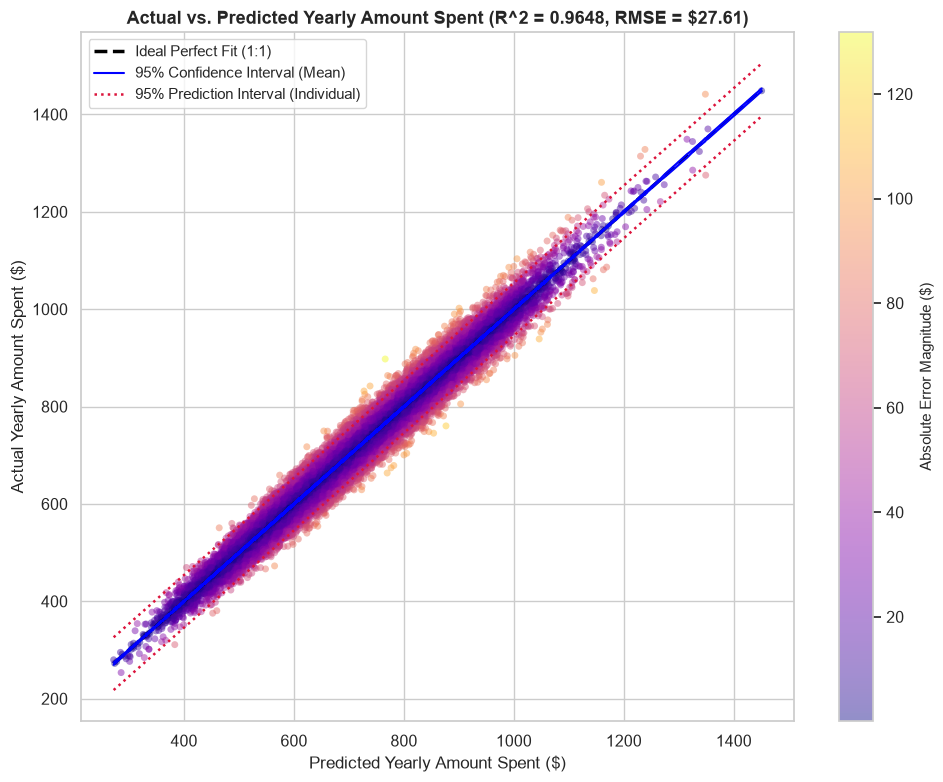

In [5]:
# Static Publication Figure: Actual vs Predicted with Interval Bands
fig, ax = plt.subplots(figsize=(10, 8))
scatter = ax.scatter(df['Predicted_Spend'], df['Yearly_Amount_Spent'], c=df['Absolute_Error'], cmap='plasma', alpha=0.45, s=25, edgecolors='none')
cbar = plt.colorbar(scatter, ax=ax)
cbar.set_label("Absolute Error Magnitude ($)", fontsize=11)

min_s = df['Predicted_Spend'].min()
max_s = df['Predicted_Spend'].max()
ax.plot([min_s, max_s], [min_s, max_s], color='black', linestyle='--', linewidth=2.5, label='Ideal Perfect Fit (1:1)')

df_sorted = df.sort_values(by='Predicted_Spend')
ax.plot(df_sorted['Predicted_Spend'], df_sorted['CI_Upper'], color='blue', linestyle='-', linewidth=1.5, label='95% Confidence Interval (Mean)')
ax.plot(df_sorted['Predicted_Spend'], df_sorted['CI_Lower'], color='blue', linestyle='-', linewidth=1.5)
ax.fill_between(df_sorted['Predicted_Spend'], df_sorted['CI_Lower'], df_sorted['CI_Upper'], color='blue', alpha=0.15)

ax.plot(df_sorted['Predicted_Spend'], df_sorted['PI_Upper'], color='crimson', linestyle=':', linewidth=1.8, label='95% Prediction Interval (Individual)')
ax.plot(df_sorted['Predicted_Spend'], df_sorted['PI_Lower'], color='crimson', linestyle=':', linewidth=1.8)

ax.set_title(f"Actual vs. Predicted Yearly Amount Spent (R^2 = {r2:.4f}, RMSE = ${rmse:.2f})", fontweight='bold', fontsize=13)
ax.set_xlabel("Predicted Yearly Amount Spent ($)", fontsize=12)
ax.set_ylabel("Actual Yearly Amount Spent ($)", fontsize=12)
ax.legend(loc='upper left', frameon=True, fontsize=10.5)

plt.tight_layout()
plt.savefig("actual_vs_predicted_error_scatter.png", dpi=300)
plt.show()

In [6]:
# Cohort summary calculation across Age, Department, and App Usage
cohort_records = []
for factor, col in [('Age Cohort', 'Age_Cohort'), ('Department', 'Department Name'), ('App Usage Tier', 'App_Usage_Cohort')]:
    grp = df.groupby(col, observed=False).agg(
        Sample_Count=('Residual', 'count'),
        Mean_Residual=('Residual', lambda x: round(x.mean(), 4)),
        Std_Residual=('Residual', lambda x: round(x.std(), 4)),
        Mean_Absolute_Error=('Absolute_Error', lambda x: round(x.mean(), 2)),
        R2_Score=('Yearly_Amount_Spent', lambda x: round(r2_score(x, df.loc[x.index, 'Predicted_Spend']), 4))
    ).reset_index()
    grp.rename(columns={col: 'Subgroup'}, inplace=True)
    grp['Factor_Category'] = factor
    cohort_records.append(grp)

df_cohorts = pd.concat(cohort_records, ignore_index=True)
df_cohorts.to_csv("systematic_bias_cohort_analysis.csv", index=False)
print("Saved cohort systematic bias analysis to systematic_bias_cohort_analysis.csv")
df_cohorts

Saved cohort systematic bias analysis to systematic_bias_cohort_analysis.csv


,Subgroup,Sample_Count,Mean_Residual,Std_Residual,Mean_Absolute_Error,R2_Score,Factor_Category
0,Gen Z / Young (18-30),3337,0.4295,23.4798,18.64,0.9356,Age Cohort
1,Early Career (31-45),11014,-0.0332,26.1959,20.92,0.9300,Age Cohort
2,Mature (46-60),6680,-0.2366,29.5166,23.54,0.9207,Age Cohort
3,Senior (61+),2434,0.2110,33.1032,26.60,0.9108,Age Cohort
4,Bottoms,3798,-0.7260,27.6818,21.94,0.9605,Department
5,Dresses,6312,0.0461,28.6183,22.65,0.9579,Department
6,Intimate,1735,-0.1408,25.6967,20.57,0.9670,Department
7,Jackets,1032,0.5249,28.6856,23.24,0.9632,Department
8,Tops,10469,0.1860,27.1651,21.60,0.9646,Department
9,Trend,119,1.8635,26.5466,20.82,0.9629,Department


In [7]:
# Formal ANOVA tests for systematic bias in residuals
# H0: Mean residual is equal across groups (no systematic bias)
anova_records = []
for factor_col in ['Age_Cohort', 'Department Name', 'App_Usage_Cohort']:
    groups = [group['Residual'].values for _, group in df.groupby(factor_col, observed=False)]
    f_stat, p_val = stats.f_oneway(*groups)
    anova_records.append({
        'Factor_Tested': factor_col,
        'F_Statistic': round(f_stat, 4),
        'p_value': f"{p_val:.4e}",
        'Systematic_Bias_Decision': 'Statistically Significant Bias Detected' if p_val < 0.05 else 'No Systematic Bias (Homogeneous Errors)'
    })
df_anova = pd.DataFrame(anova_records)
df_anova.to_csv("residual_bias_anova_tests.csv", index=False)
print("Saved residual bias ANOVA tests to residual_bias_anova_tests.csv")
df_anova

Saved residual bias ANOVA tests to residual_bias_anova_tests.csv


,Factor_Tested,F_Statistic,p_value,Systematic_Bias_Decision
0,Age_Cohort,0.4856,6.9230e-01,No Systematic Bias (Homogeneous Errors)
1,Department Name,0.8159,5.3806e-01,No Systematic Bias (Homogeneous Errors)
2,App_Usage_Cohort,0.3097,7.3364e-01,No Systematic Bias (Homogeneous Errors)


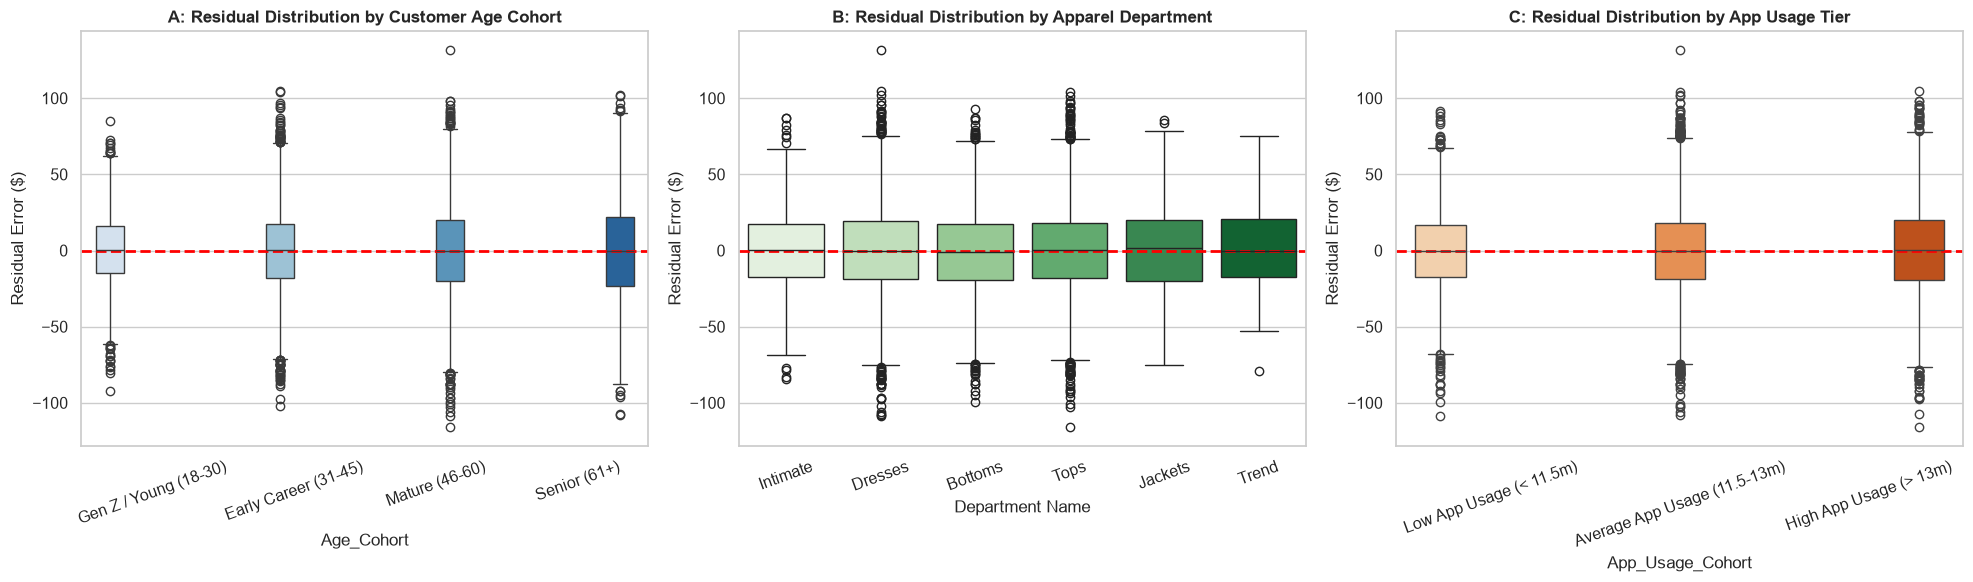

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

sns.boxplot(data=df, x='Age_Cohort', y='Residual', hue='Age_Cohort', palette='Blues', legend=False, ax=axes[0])
axes[0].axhline(0, color='red', linestyle='--', linewidth=2)
axes[0].set_title("A: Residual Distribution by Customer Age Cohort", fontweight='bold')
axes[0].set_ylabel("Residual Error ($)")
axes[0].tick_params(axis='x', rotation=20)

sns.boxplot(data=df, x='Department Name', y='Residual', hue='Department Name', palette='Greens', legend=False, ax=axes[1])
axes[1].axhline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_title("B: Residual Distribution by Apparel Department", fontweight='bold')
axes[1].set_ylabel("Residual Error ($)")
axes[1].tick_params(axis='x', rotation=20)

sns.boxplot(data=df, x='App_Usage_Cohort', y='Residual', hue='App_Usage_Cohort', palette='Oranges', legend=False, ax=axes[2])
axes[2].axhline(0, color='red', linestyle='--', linewidth=2)
axes[2].set_title("C: Residual Distribution by App Usage Tier", fontweight='bold')
axes[2].set_ylabel("Residual Error ($)")
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig("systematic_bias_by_category_and_age.png", dpi=300)
plt.show()

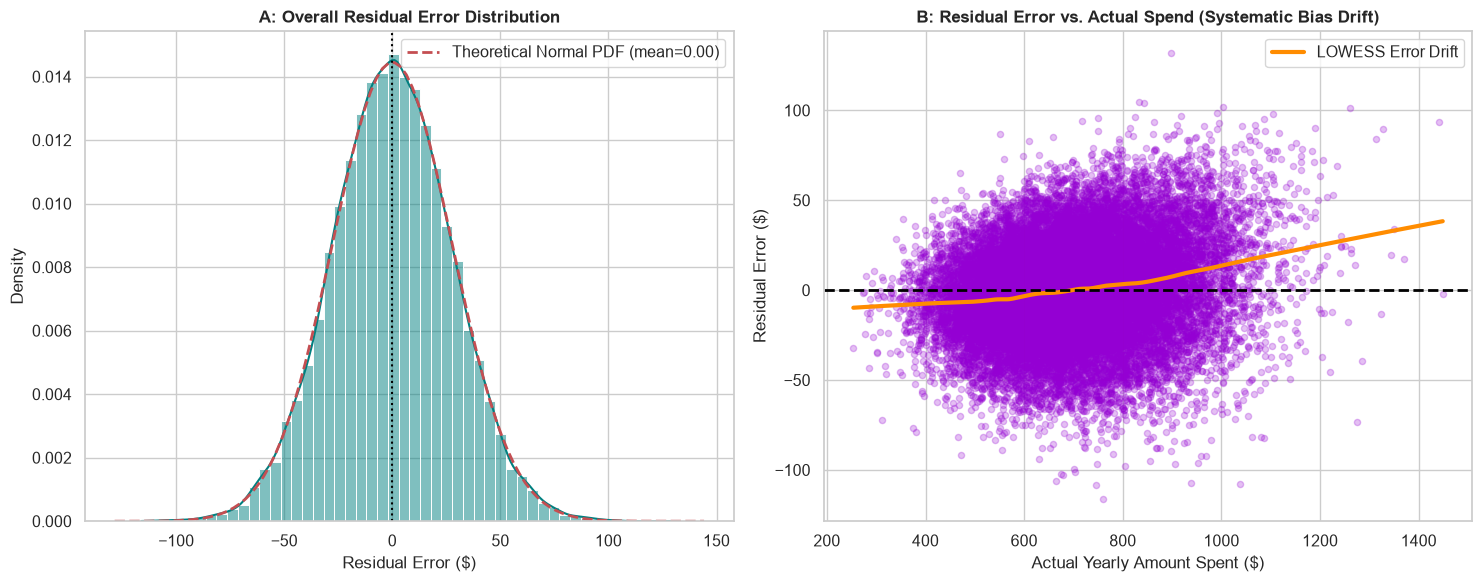

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Histogram with Gaussian fit
sns.histplot(df['Residual'], bins=50, kde=True, color='teal', stat="density", ax=axes[0])
xmin, xmax = axes[0].get_xlim()
x_norm = np.linspace(xmin, xmax, 100)
p_norm = stats.norm.pdf(x_norm, df['Residual'].mean(), df['Residual'].std())
axes[0].plot(x_norm, p_norm, 'r--', linewidth=2, label=f'Theoretical Normal PDF (mean={df["Residual"].mean():.2f})')
axes[0].axvline(0, color='black', linestyle=':', linewidth=1.5)
axes[0].set_title("A: Overall Residual Error Distribution", fontweight='bold')
axes[0].set_xlabel("Residual Error ($)")
axes[0].legend()

# Cumulative Error vs Actual Spend (Detecting High-Spend Systematic Underprediction)
res_roll = df.sort_values(by='Yearly_Amount_Spent')
lowess = sm.nonparametric.lowess(res_roll['Residual'], res_roll['Yearly_Amount_Spent'], frac=0.2)
axes[1].scatter(res_roll['Yearly_Amount_Spent'], res_roll['Residual'], alpha=0.25, color='darkviolet', s=20)
axes[1].plot(lowess[:, 0], lowess[:, 1], color='darkorange', linewidth=3, label='LOWESS Error Drift')
axes[1].axhline(0, color='black', linestyle='--', linewidth=2)
axes[1].set_title("B: Residual Error vs. Actual Spend (Systematic Bias Drift)", fontweight='bold')
axes[1].set_xlabel("Actual Yearly Amount Spent ($)")
axes[1].set_ylabel("Residual Error ($)")
axes[1].legend()

plt.tight_layout()
plt.savefig("residual_distribution_normality_bias.png", dpi=300)
plt.show()